<a href="https://colab.research.google.com/github/meherunmary/dry-bean-classification-ml-project-infinite-bite/blob/main/Infinite_Byte.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dry Bean Classification Using KNN and SVM
## 1. Setup
Import the libraries used in this notebook.

In [ ]:
#@title Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import warnings
warnings.filterwarnings("ignore")

For Import Dataset

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Dry_Bean_Dataset.xlsx to Dry_Bean_Dataset (1).xlsx


## 2. Data Loading
Load the Dry Bean Dataset (UCI Machine Learning Repository, 13,611 samples, 16 features, 7 classes).

In [ ]:
ib = pd.read_excel("Dry_Bean_Dataset.xlsx")
ib.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


Check Row and Column

In [ ]:
ib.shape

(13611, 17)

## 3. Data Inspection
Check the data types, missing values, and duplicate rows.

In [ ]:
ib.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  object 
dtypes: float64(1

In [ ]:
ib.isnull().sum()

,0
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRation,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0


In [ ]:
ib.duplicated().sum()

np.int64(68)

### Removing duplicates
68 duplicate rows were found

In [ ]:
ib1 = ib.drop_duplicates()

print("Before:", ib.shape)
print("After:", ib1.shape)
print("Removed:", len(ib) - len(ib1))

Before: (13611, 17)
After: (13543, 17)
Removed: 68


Reset

In [ ]:
ib = ib1.reset_index(drop=True)
ib.shape

(13543, 17)

## 4. Exploratory Data Analysis

In [ ]:
ib["Class"].value_counts()

,count
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1860
CALI,1630
BARBUNYA,1322
BOMBAY,522


In [ ]:
(ib["Class"].value_counts(normalize=True) * 100).round(2)

,proportion
Class,
DERMASON,26.18
SIRA,19.46
SEKER,14.97
HOROZ,13.73
CALI,12.04
BARBUNYA,9.76
BOMBAY,3.85


In [ ]:
summary = ib.describe().T
summary

,count,mean,std,min,25%,50%,75%,max
Area,13543.0,53048.460385,29392.438324,20420.000000,36282.500000,44580.000000,61382.000000,254616.000000
Perimeter,13543.0,854.993406,214.722684,524.736000,703.230000,793.896000,977.146500,1985.370000
MajorAxisLength,13543.0,319.895602,85.809260,183.601165,253.086806,296.404589,376.312489,738.860153
MinorAxisLength,13543.0,202.365321,45.051632,122.512653,175.886357,192.491117,217.245403,460.198497
AspectRation,13543.0,1.581075,0.245245,1.024868,1.430662,1.549860,1.703916,2.430306
Eccentricity,13543.0,0.750315,0.091858,0.218951,0.715144,0.763997,0.809671,0.911423
ConvexArea,13543.0,53767.986709,29844.248525,20684.000000,36673.000000,45122.000000,62360.000000,263261.000000
EquivDiameter,13543.0,253.034094,59.307709,161.243764,214.933277,238.245711,279.560351,569.374358
Extent,13543.0,0.749829,0.048939,0.555315,0.718735,0.759903,0.786849,0.866195
Solidity,13543.0,0.987152,0.004650,0.919246,0.985678,0.988288,0.990019,0.994677


In [ ]:
summary_sorted = summary.sort_values(by="mean", ascending=False)
summary_sorted

,count,mean,std,min,25%,50%,75%,max
ConvexArea,13543.0,53767.986709,29844.248525,20684.000000,36673.000000,45122.000000,62360.000000,263261.000000
Area,13543.0,53048.460385,29392.438324,20420.000000,36282.500000,44580.000000,61382.000000,254616.000000
Perimeter,13543.0,854.993406,214.722684,524.736000,703.230000,793.896000,977.146500,1985.370000
MajorAxisLength,13543.0,319.895602,85.809260,183.601165,253.086806,296.404589,376.312489,738.860153
EquivDiameter,13543.0,253.034094,59.307709,161.243764,214.933277,238.245711,279.560351,569.374358
MinorAxisLength,13543.0,202.365321,45.051632,122.512653,175.886357,192.491117,217.245403,460.198497
AspectRation,13543.0,1.581075,0.245245,1.024868,1.430662,1.549860,1.703916,2.430306
ShapeFactor4,13543.0,0.995078,0.004347,0.947687,0.993720,0.996393,0.997891,0.999733
Solidity,13543.0,0.987152,0.004650,0.919246,0.985678,0.988288,0.990019,0.994677
roundness,13543.0,0.873671,0.059393,0.489618,0.833410,0.883490,0.917031,0.990685


###Summary statistics and correlation

In [ ]:
corr = ib.drop(columns="Class").corr()
corr.round(2)

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
Area,1.00,0.97,0.93,0.95,0.24,0.27,1.00,0.98,0.05,-0.20,-0.36,-0.27,-0.85,-0.64,-0.27,-0.36
Perimeter,0.97,1.00,0.98,0.91,0.39,0.39,0.97,0.99,-0.02,-0.30,-0.55,-0.41,-0.87,-0.77,-0.41,-0.43
MajorAxisLength,0.93,0.98,1.00,0.83,0.55,0.54,0.93,0.96,-0.08,-0.28,-0.60,-0.57,-0.78,-0.86,-0.57,-0.48
MinorAxisLength,0.95,0.91,0.83,1.00,-0.01,0.02,0.95,0.95,0.15,-0.16,-0.21,-0.02,-0.95,-0.48,-0.02,-0.27
AspectRation,0.24,0.39,0.55,-0.01,1.00,0.92,0.25,0.31,-0.37,-0.27,-0.76,-0.99,0.02,-0.84,-0.98,-0.45
Eccentricity,0.27,0.39,0.54,0.02,0.92,1.00,0.27,0.32,-0.32,-0.30,-0.72,-0.97,0.02,-0.86,-0.98,-0.45
ConvexArea,1.00,0.97,0.93,0.95,0.25,0.27,1.00,0.99,0.05,-0.21,-0.36,-0.27,-0.85,-0.64,-0.28,-0.36
EquivDiameter,0.98,0.99,0.96,0.95,0.31,0.32,0.99,1.00,0.03,-0.23,-0.44,-0.33,-0.89,-0.71,-0.33,-0.39
Extent,0.05,-0.02,-0.08,0.15,-0.37,-0.32,0.05,0.03,1.00,0.19,0.34,0.35,-0.14,0.24,0.35,0.15
Solidity,-0.20,-0.30,-0.28,-0.16,-0.27,-0.30,-0.21,-0.23,0.19,1.00,0.61,0.30,0.15,0.34,0.31,0.70


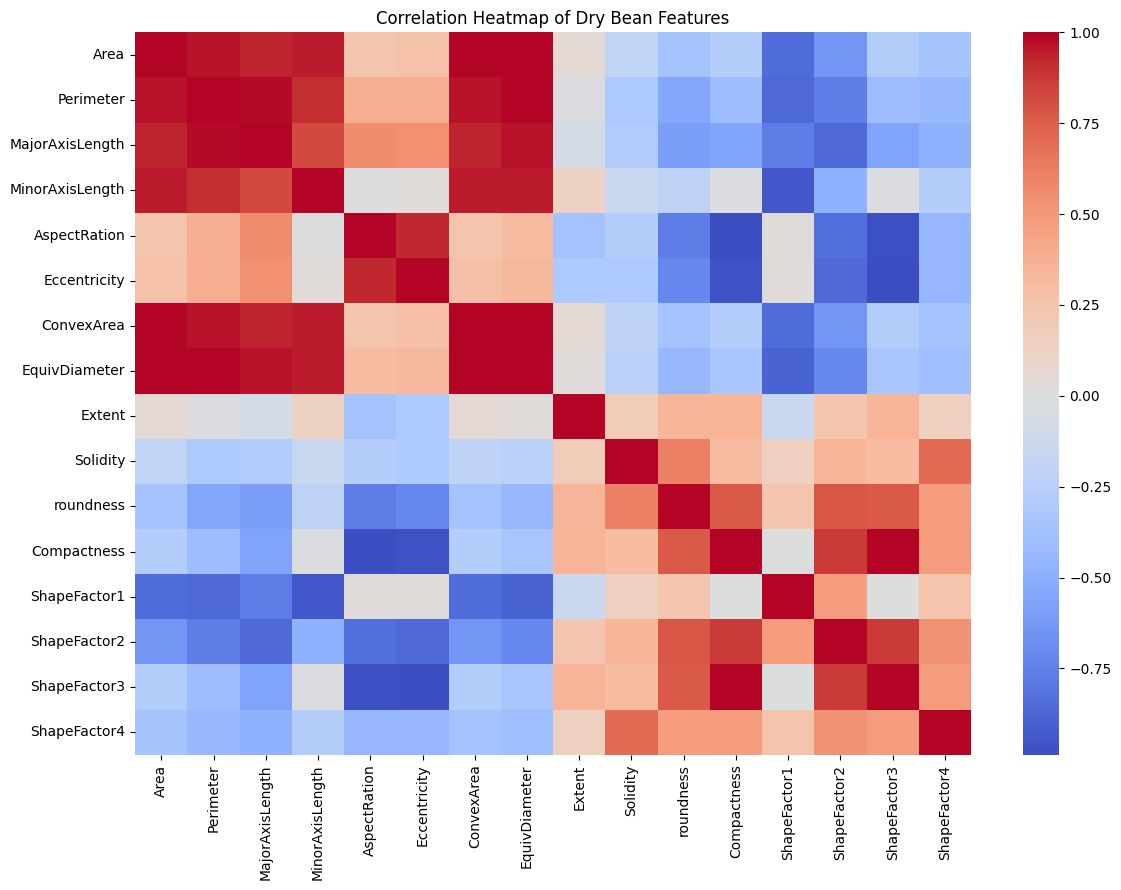

In [ ]:
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap of Dry Bean Features")
plt.tight_layout()
plt.show()

In [ ]:
X = ib.drop(columns="Class")
y = ib["Class"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (13543, 16)
y shape: (13543,)


### Highly correlated feature pairs
Feature pairs with |r| >= 0.9

In [ ]:
corr = X.corr()


upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

pairs = upper.stack().reset_index()
pairs.columns = ["Feature 1", "Feature 2", "Correlation"]

high_pairs = pairs[pairs["Correlation"].abs() >= 0.9]
high_pairs = high_pairs.sort_values(by="Correlation", ascending=False)
high_pairscorr = X.corr()


upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

pairs = upper.stack().reset_index()
pairs.columns = ["Feature 1", "Feature 2", "Correlation"]

high_pairs = pairs[pairs["Correlation"].abs() >= 0.9]
high_pairs = high_pairs.sort_values(by="Correlation", ascending=False)
high_pairs

,Feature 1,Feature 2,Correlation
5,Area,ConvexArea,0.999940
112,Compactness,ShapeFactor3,0.998684
20,Perimeter,EquivDiameter,0.991453
75,ConvexArea,EquivDiameter,0.985255
6,Area,EquivDiameter,0.984998
15,Perimeter,MajorAxisLength,0.977561
19,Perimeter,ConvexArea,0.967871
0,Area,Perimeter,0.966908
33,MajorAxisLength,EquivDiameter,0.962271
2,Area,MinorAxisLength,0.952041


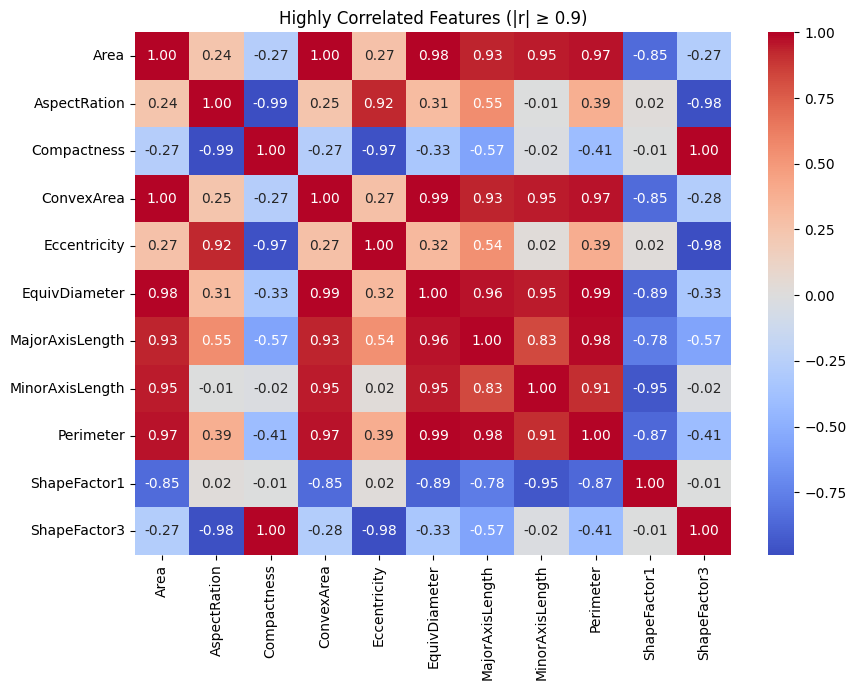

In [ ]:
high_features = sorted(set(high_pairs["Feature 1"]) | set(high_pairs["Feature 2"]))

plt.figure(figsize=(9, 7))
sns.heatmap(corr.loc[high_features, high_features],
            annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Highly Correlated Features (|r| ≥ 0.9)")
plt.tight_layout()
plt.show()

### Outlier check

In [ ]:
features = ib.drop(columns="Class")

Q1 = features.quantile(0.25)
Q3 = features.quantile(0.75)
IQR = Q3 - Q1

outliers = ((features < (Q1 - 1.5 * IQR)) | (features > (Q3 + 1.5 * IQR)))

outlier_summary = pd.DataFrame({
    "Outlier count": outliers.sum(),
    "Percentage": (outliers.sum() / len(features) * 100).round(2)
}).sort_values(by="Outlier count", ascending=False)

outlier_summary

,Outlier count,Percentage
Eccentricity,833,6.15
Solidity,774,5.72
ShapeFactor4,760,5.61
MinorAxisLength,567,4.19
Area,551,4.07
ConvexArea,549,4.05
ShapeFactor1,533,3.94
EquivDiameter,526,3.88
Perimeter,500,3.69
AspectRation,485,3.58


### Feature distributions by class
Box plots of Area and ShapeFactor1 for each bean class.

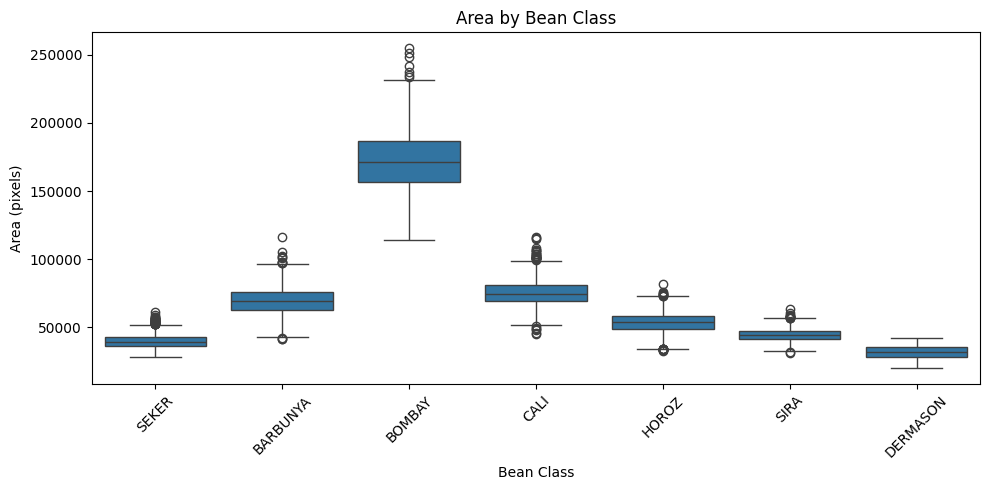

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=ib, x="Class", y="Area")
plt.title("Area by Bean Class")
plt.xlabel("Bean Class")
plt.ylabel("Area (pixels)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

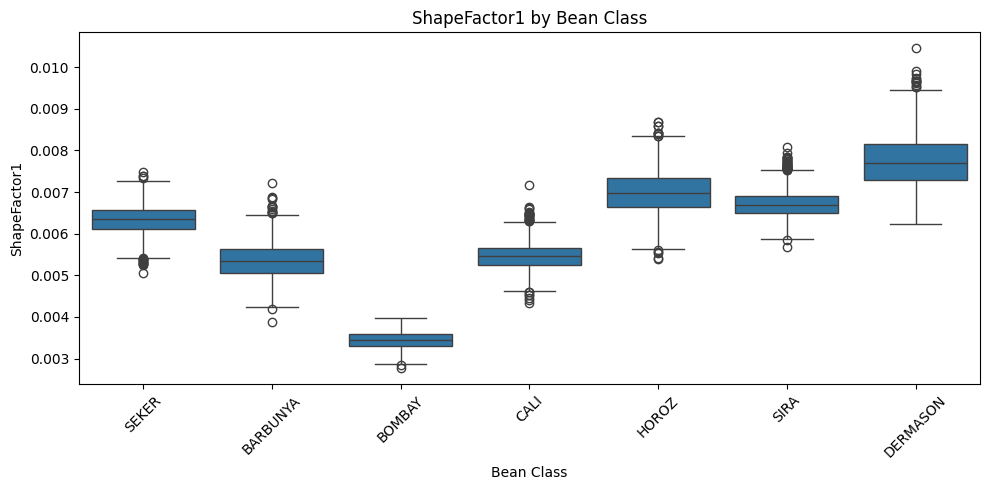

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=ib, x="Class", y="ShapeFactor1")
plt.title("ShapeFactor1 by Bean Class")
plt.xlabel("Bean Class")
plt.ylabel("ShapeFactor1")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### DERMASON vs SIRA

In [ ]:
import sys
import sklearn
print("Python:", sys.version)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
pandas: 2.2.3
numpy: 2.4.6
scikit-learn: 1.6.1


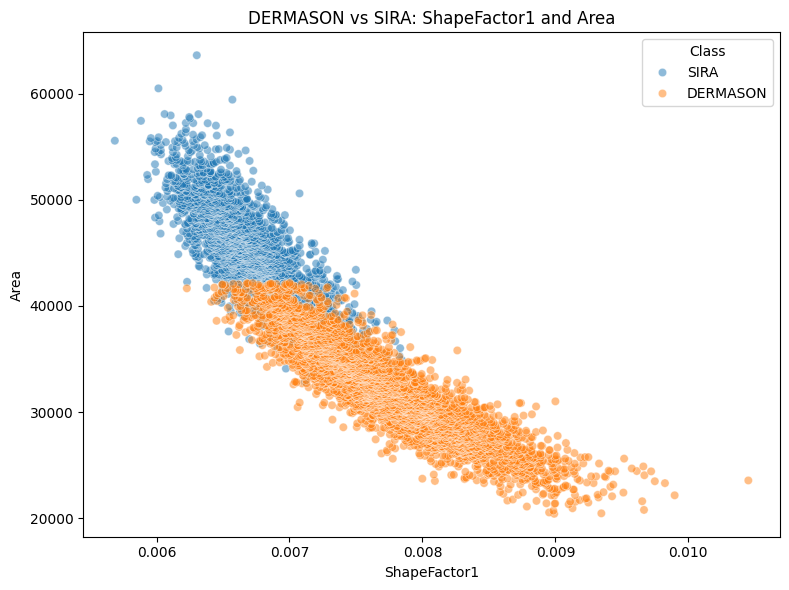

In [ ]:
subset = ib[ib["Class"].isin(["DERMASON", "SIRA"])]

plt.figure(figsize=(8, 6))
sns.scatterplot(data=subset, x="ShapeFactor1", y="Area", hue="Class", alpha=0.5)
plt.title("DERMASON vs SIRA: ShapeFactor1 and Area")
plt.tight_layout()
plt.show()

### Histograms of all features

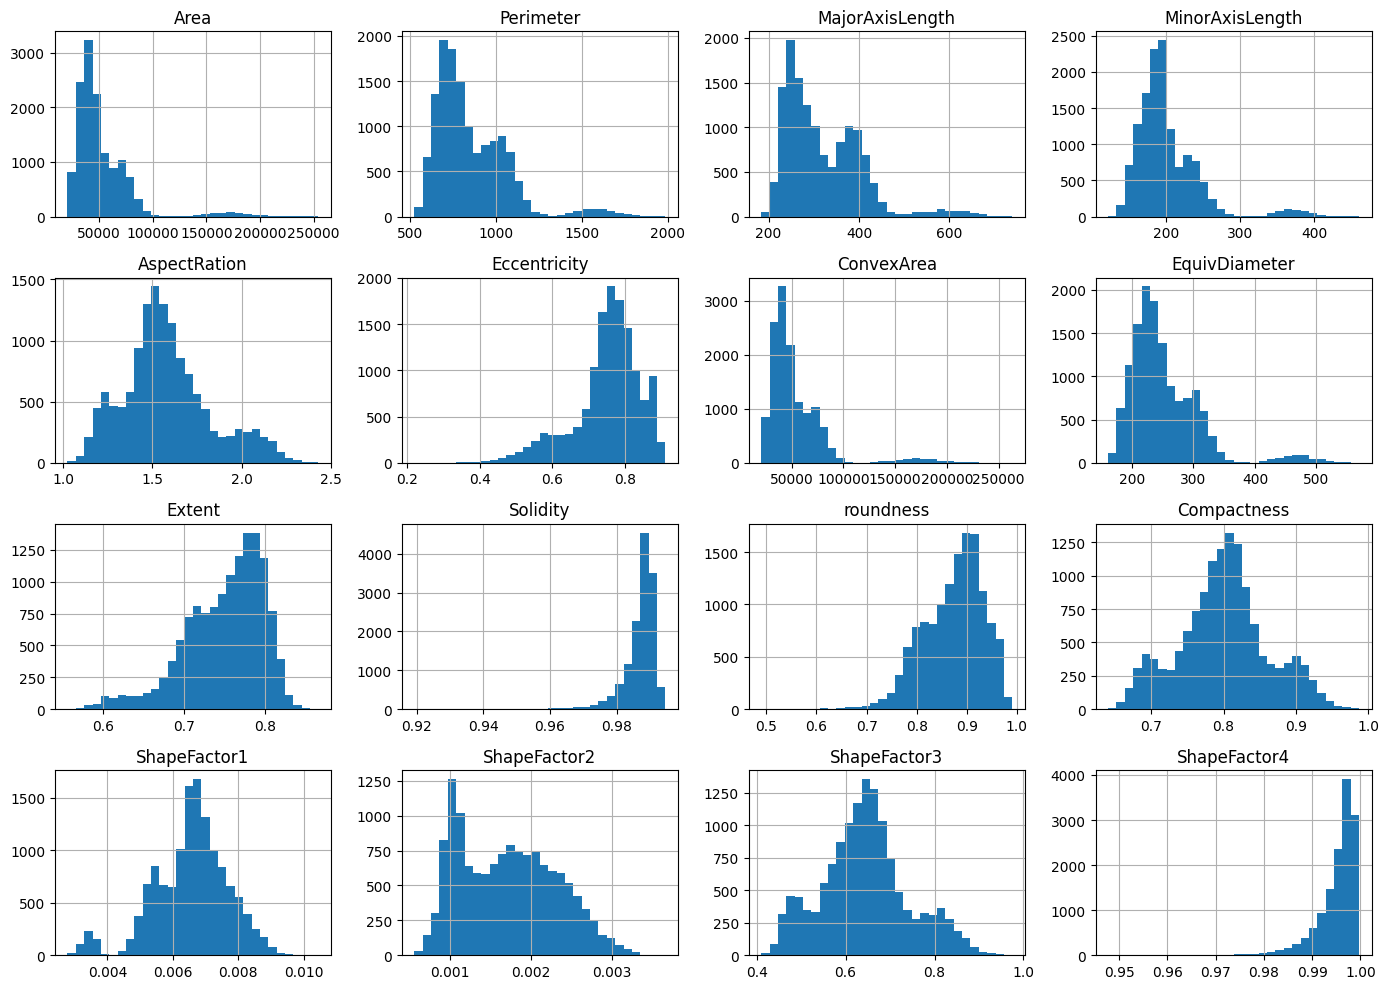

In [ ]:
ib.drop(columns="Class").hist(bins=30, figsize=(14, 10))
plt.tight_layout()
plt.show()

### Train-test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (10834, 16)
X_test: (2709, 16)


In [ ]:
print((y_train.value_counts(normalize=True) * 100).round(2))
print((y_test.value_counts(normalize=True) * 100).round(2))

Class
DERMASON    26.19
SIRA        19.47
SEKER       14.96
HOROZ       13.73
CALI        12.04
BARBUNYA     9.76
BOMBAY       3.86
Name: proportion, dtype: float64
Class
DERMASON    26.17
SIRA        19.45
SEKER       14.99
HOROZ       13.73
CALI        12.03
BARBUNYA     9.78
BOMBAY       3.84
Name: proportion, dtype: float64


In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train mean (approx):", X_train_scaled.mean().round(2))
print("Train std (approx):", X_train_scaled.std().round(2))

Train mean (approx): -0.0
Train std (approx): 1.0


In [ ]:
from sklearn.model_selection import cross_val_score

k_values = range(1, 26)
cv_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(knn, X_train_scaled, y_train, cv=5).mean()
    cv_scores.append(score)

best_k = k_values[cv_scores.index(max(cv_scores))]
print("Best k:", best_k)
print("Best CV accuracy:", round(max(cv_scores), 4))

Best k: 13
Best CV accuracy: 0.9259


In [ ]:
knn_final = KNeighborsClassifier(n_neighbors=13)
knn_final.fit(X_train_scaled, y_train)

y_train_pred = knn_final.predict(X_train_scaled)
y_test_pred = knn_final.predict(X_test_scaled)

print("Train accuracy:", round(accuracy_score(y_train, y_train_pred), 4))
print("Test accuracy:", round(accuracy_score(y_test, y_test_pred), 4))
print()
print(classification_report(y_test, y_test_pred))

Train accuracy: 0.9347
Test accuracy: 0.9162

              precision    recall  f1-score   support

    BARBUNYA       0.95      0.88      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.90      0.96      0.93       326
    DERMASON       0.91      0.91      0.91       709
       HOROZ       0.96      0.93      0.95       372
       SEKER       0.94      0.94      0.94       406
        SIRA       0.85      0.87      0.86       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



## KNN: confusion matrix

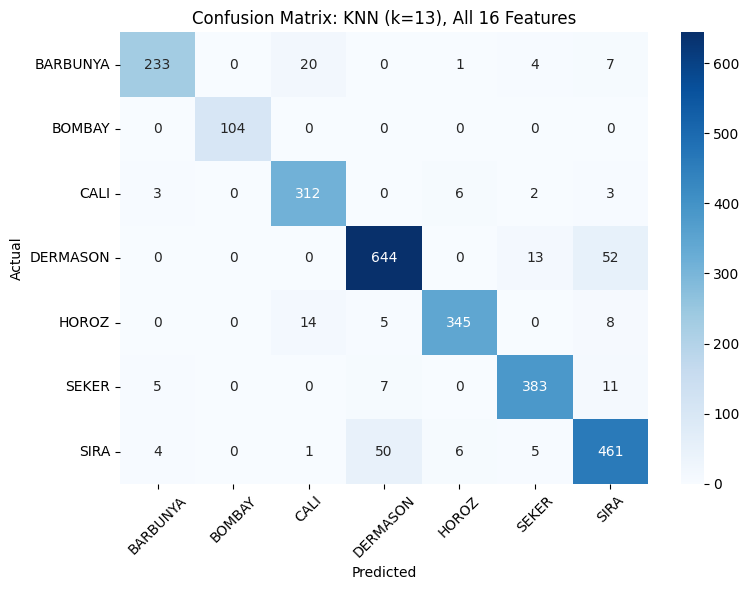

In [ ]:
cm_knn = confusion_matrix(y_test, y_test_pred, labels=knn_final.classes_)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Blues",
            xticklabels=knn_final.classes_, yticklabels=knn_final.classes_)
plt.title("Confusion Matrix: KNN (k=13), All 16 Features")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### SVM: selecting C and gamma

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "C": [1, 10, 100],
    "gamma": ["scale", 0.01, 0.1]
}

grid_svm = GridSearchCV(SVC(kernel="rbf"), param_grid, cv=3, n_jobs=-1)
grid_svm.fit(X_train_scaled, y_train)

print("Best parameters:", grid_svm.best_params_)
print("Best CV accuracy:", round(grid_svm.best_score_, 4))

Best parameters: {'C': 10, 'gamma': 'scale'}
Best CV accuracy: 0.9322


In [ ]:
svm_final = SVC(kernel="rbf", C=10, gamma="scale")
svm_final.fit(X_train_scaled, y_train)

y_train_pred_svm = svm_final.predict(X_train_scaled)
y_test_pred_svm = svm_final.predict(X_test_scaled)

print("Train accuracy:", round(accuracy_score(y_train, y_train_pred_svm), 4))
print("Test accuracy:", round(accuracy_score(y_test, y_test_pred_svm), 4))
print()
print(classification_report(y_test, y_test_pred_svm))

Train accuracy: 0.9397
Test accuracy: 0.9236

              precision    recall  f1-score   support

    BARBUNYA       0.92      0.91      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.94      0.93       326
    DERMASON       0.91      0.92      0.92       709
       HOROZ       0.97      0.94      0.95       372
       SEKER       0.94      0.95      0.95       406
        SIRA       0.87      0.87      0.87       527

    accuracy                           0.92      2709
   macro avg       0.94      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



### SVM: confusion matrix

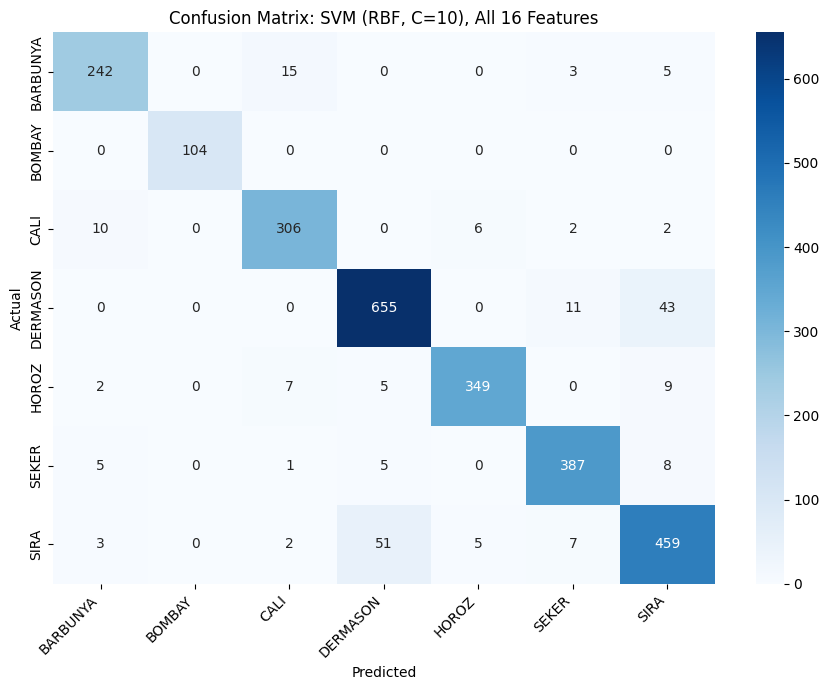

In [ ]:
cm_svm = confusion_matrix(y_test, y_test_pred_svm, labels=svm_final.classes_)

plt.figure(figsize=(9, 7))
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Blues",
            xticklabels=svm_final.classes_, yticklabels=svm_final.classes_)
plt.title("Confusion Matrix: SVM (RBF, C=10), All 16 Features")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Feature Engineering

In [ ]:
corr_train = X_train.corr()

upper_train = corr_train.where(np.triu(np.ones(corr_train.shape), k=1).astype(bool))

pairs_train = upper_train.stack().reset_index()
pairs_train.columns = ["Feature 1", "Feature 2", "Correlation"]

high_pairs_train = pairs_train[pairs_train["Correlation"].abs() >= 0.9]
high_pairs_train = high_pairs_train.sort_values(by="Correlation", ascending=False)
high_pairs_train

,Feature 1,Feature 2,Correlation
5,Area,ConvexArea,0.999941
112,Compactness,ShapeFactor3,0.998682
20,Perimeter,EquivDiameter,0.991581
75,ConvexArea,EquivDiameter,0.985364
6,Area,EquivDiameter,0.985077
15,Perimeter,MajorAxisLength,0.977719
19,Perimeter,ConvexArea,0.968076
0,Area,Perimeter,0.967091
33,MajorAxisLength,EquivDiameter,0.962176
2,Area,MinorAxisLength,0.952422


Reduced feature set (8 features)

In [ ]:
selected = ["Area", "AspectRation", "Extent", "Solidity",
            "roundness", "ShapeFactor1", "ShapeFactor2", "ShapeFactor4"]

X_train_red = X_train[selected]
X_test_red = X_test[selected]

print("Reduced X_train:", X_train_red.shape)
print("Reduced X_test:", X_test_red.shape)

Reduced X_train: (10834, 8)
Reduced X_test: (2709, 8)


In [ ]:
scaler_red = StandardScaler()
X_train_red_scaled = scaler_red.fit_transform(X_train_red)
X_test_red_scaled = scaler_red.transform(X_test_red)

print("Train mean (approx):", X_train_red_scaled.mean().round(2))
print("Train std (approx):", X_train_red_scaled.std().round(2))

Train mean (approx): -0.0
Train std (approx): 1.0


KNN for 8 feature

In [ ]:
k_values = range(1, 26)
cv_scores_red = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(knn, X_train_red_scaled, y_train, cv=5).mean()
    cv_scores_red.append(score)

best_k_red = k_values[cv_scores_red.index(max(cv_scores_red))]
print("Best k:", best_k_red)
print("Best CV accuracy:", round(max(cv_scores_red), 4))

Best k: 10
Best CV accuracy: 0.9262


In [ ]:
knn_red = KNeighborsClassifier(n_neighbors=10)
knn_red.fit(X_train_red_scaled, y_train)

y_train_pred_knn_red = knn_red.predict(X_train_red_scaled)
y_test_pred_knn_red = knn_red.predict(X_test_red_scaled)

print("Train accuracy:", round(accuracy_score(y_train, y_train_pred_knn_red), 4))
print("Test accuracy:", round(accuracy_score(y_test, y_test_pred_knn_red), 4))
print()
print(classification_report(y_test, y_test_pred_knn_red))

Train accuracy: 0.9382
Test accuracy: 0.9136

              precision    recall  f1-score   support

    BARBUNYA       0.93      0.89      0.91       265
      BOMBAY       1.00      0.99      1.00       104
        CALI       0.89      0.95      0.92       326
    DERMASON       0.90      0.92      0.91       709
       HOROZ       0.97      0.92      0.95       372
       SEKER       0.94      0.94      0.94       406
        SIRA       0.86      0.85      0.86       527

    accuracy                           0.91      2709
   macro avg       0.93      0.92      0.93      2709
weighted avg       0.91      0.91      0.91      2709



SVM

In [ ]:
grid_svm_red = GridSearchCV(SVC(kernel="rbf"), param_grid, cv=3, n_jobs=-1)
grid_svm_red.fit(X_train_red_scaled, y_train)

print("Best parameters:", grid_svm_red.best_params_)
print("Best CV accuracy:", round(grid_svm_red.best_score_, 4))

Best parameters: {'C': 10, 'gamma': 'scale'}
Best CV accuracy: 0.9322


In [ ]:
svm_red = SVC(kernel="rbf", C=10, gamma="scale")
svm_red.fit(X_train_red_scaled, y_train)

y_train_pred_svm_red = svm_red.predict(X_train_red_scaled)
y_test_pred_svm_red = svm_red.predict(X_test_red_scaled)

print("Train accuracy:", round(accuracy_score(y_train, y_train_pred_svm_red), 4))
print("Test accuracy:", round(accuracy_score(y_test, y_test_pred_svm_red), 4))
print()
print(classification_report(y_test, y_test_pred_svm_red))

Train accuracy: 0.9427
Test accuracy: 0.9236

              precision    recall  f1-score   support

    BARBUNYA       0.92      0.90      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.94      0.93       326
    DERMASON       0.92      0.93      0.92       709
       HOROZ       0.97      0.94      0.95       372
       SEKER       0.94      0.95      0.95       406
        SIRA       0.87      0.87      0.87       527

    accuracy                           0.92      2709
   macro avg       0.94      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



4-fold Cross-Validation

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline

skf = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)

models = {
    "KNN (k=13)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=13)),
    "SVM (C=10)": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale")),
}

for name, model in models.items():
    res = cross_validate(model, X, y, cv=skf,
                         scoring=["accuracy", "f1_macro"])
    print(name)
    print("  Accuracy per fold:", res["test_accuracy"].round(4))
    print("  Mean accuracy:", res["test_accuracy"].mean().round(4),
          "+/-", res["test_accuracy"].std().round(4))
    print("  Mean macro F1:", res["test_f1_macro"].mean().round(4))

KNN (k=13)
  Accuracy per fold: [0.9152 0.9203 0.9297 0.9232]
  Mean accuracy: 0.9221 +/- 0.0052
  Mean macro F1: 0.9341
SVM (C=10)
  Accuracy per fold: [0.9209 0.9276 0.9386 0.9323]
  Mean accuracy: 0.9299 +/- 0.0065
  Mean macro F1: 0.9409


Cross-validation with the reduced feature set

In [ ]:
X_red = X[selected]

models_red = {
    "KNN (k=10), 8 features": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=10)),
    "SVM (C=10), 8 features": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale")),
}

for name, model in models_red.items():
    res = cross_validate(model, X_red, y, cv=skf,
                         scoring=["accuracy", "f1_macro"])
    print(name)
    print("  Accuracy per fold:", res["test_accuracy"].round(4))
    print("  Mean accuracy:", res["test_accuracy"].mean().round(4),
          "+/-", res["test_accuracy"].std().round(4))
    print("  Mean macro F1:", res["test_f1_macro"].mean().round(4))

KNN (k=10), 8 features
  Accuracy per fold: [0.9182 0.9203 0.9306 0.9261]
  Mean accuracy: 0.9238 +/- 0.0049
  Mean macro F1: 0.9357
SVM (C=10), 8 features
  Accuracy per fold: [0.9235 0.9294 0.9403 0.9338]
  Mean accuracy: 0.9318 +/- 0.0062
  Mean macro F1: 0.9427
